# 第089讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: /workspace/scratch/1577d0a62398/tutorials-20261019/machine-learning/units/089


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "axis_probe": {
    "bn_train_companion_difference": 5.291499614715576,
    "ln_companion_difference": 0.0,
    "bn_eval_companion_difference": 0.0,
    "bn_eval_shift_difference": 9.4830904006958,
    "ln_shift_difference": 0.0
  },
  "dropout_probe": {
    "p": 0.25,
    "input": 3.0,
    "train_mean": 3.0049800872802734,
    "train_var": 2.9900152683258057,
    "expected_mean": 3.0,
    "expected_variance": 3.0,
    "eval_max_error": 0.0
  },
  "validation_last": {
    "none_drop0.0": [
      0.6090970039367676,
      0.5923820734024048,
      0.686505138874054
    ],
    "none_drop0.35": [
      0.694281816482544,
      0.678791344165802,
      0.8293865323066711
    ],
    "ln_drop0.0": [
      0.8853813409805298,
      0.8673604726791382,
      0.909692108631134
    ],
    "ln_drop0.35": [
      0.7703808546066284,
      0.8440244793891907,
      0.9204959273338318
    ]
  }
}

Script exit: 0


In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_axes (test_experiment.Tests.test_axes) ... ok
test_dropout (test_experiment.Tests.test_dropout) ... ok
test_training_only_standardization (test_experiment.Tests.test_training_only_standardization) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.193s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['environment', 'protocol', 'axis_probe', 'dropout_probe', 'runs', 'batch_probe']


01_factorial.png
02_normalization_axes.png
03_dropout_batch.png


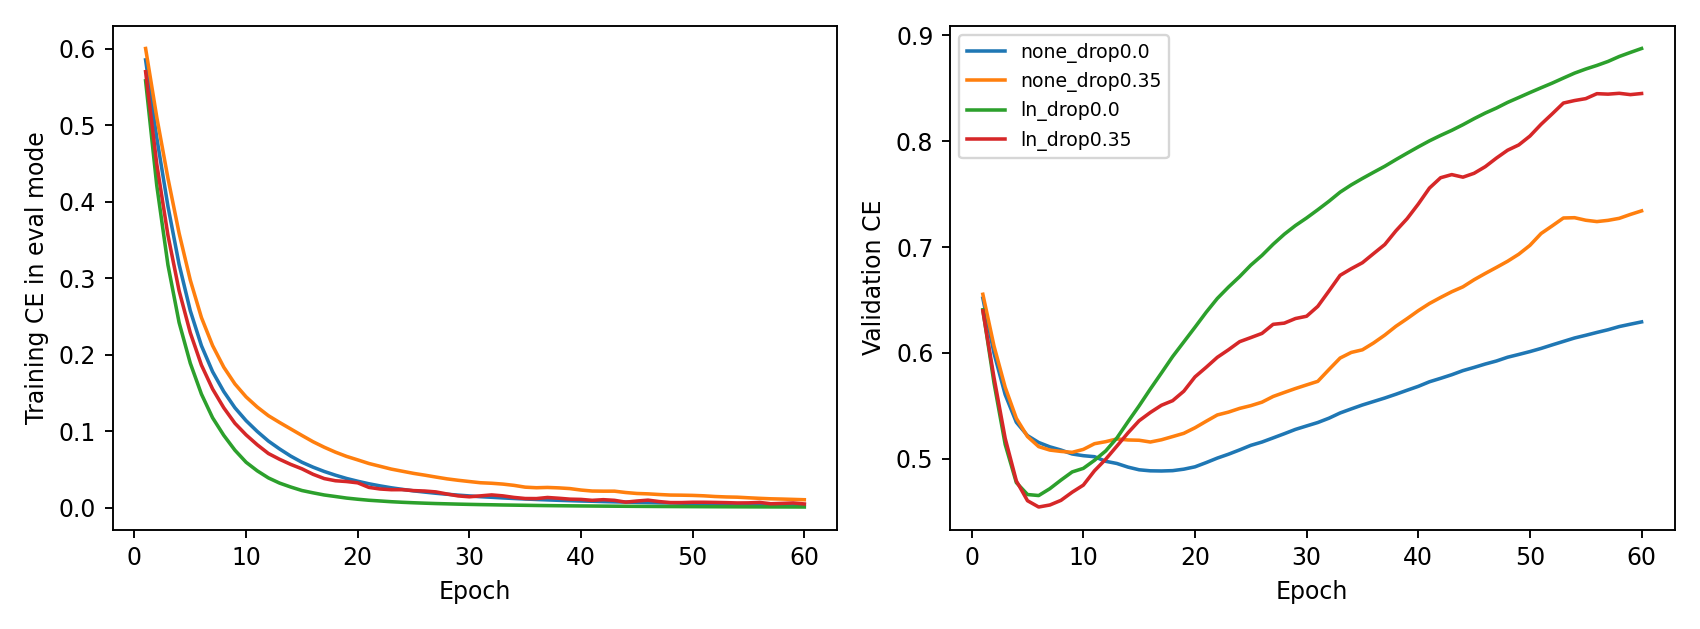

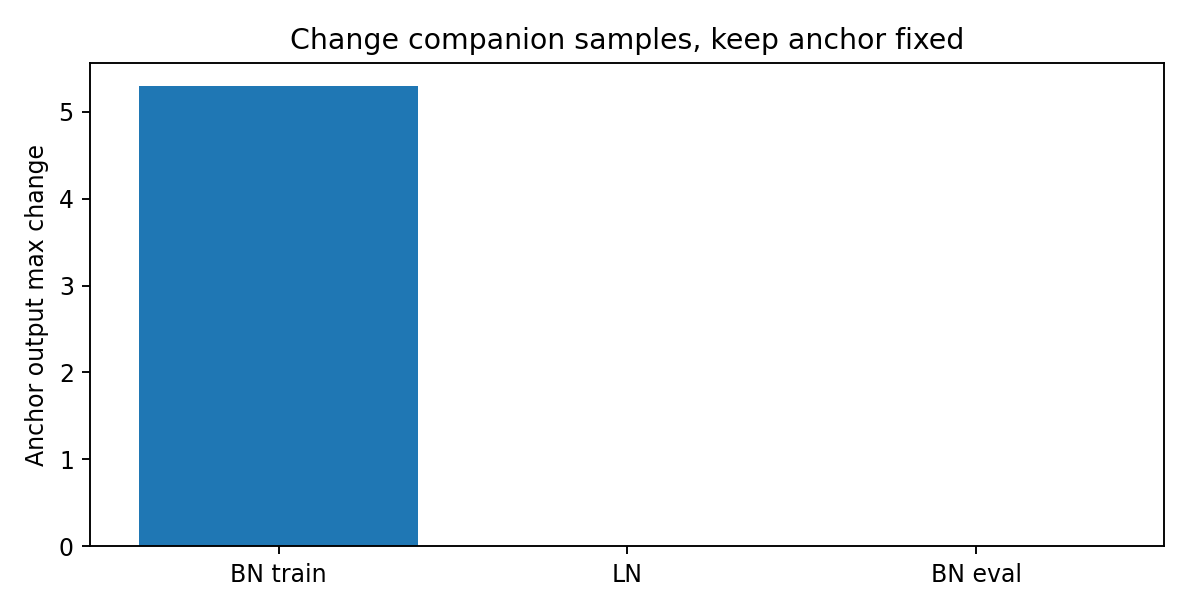

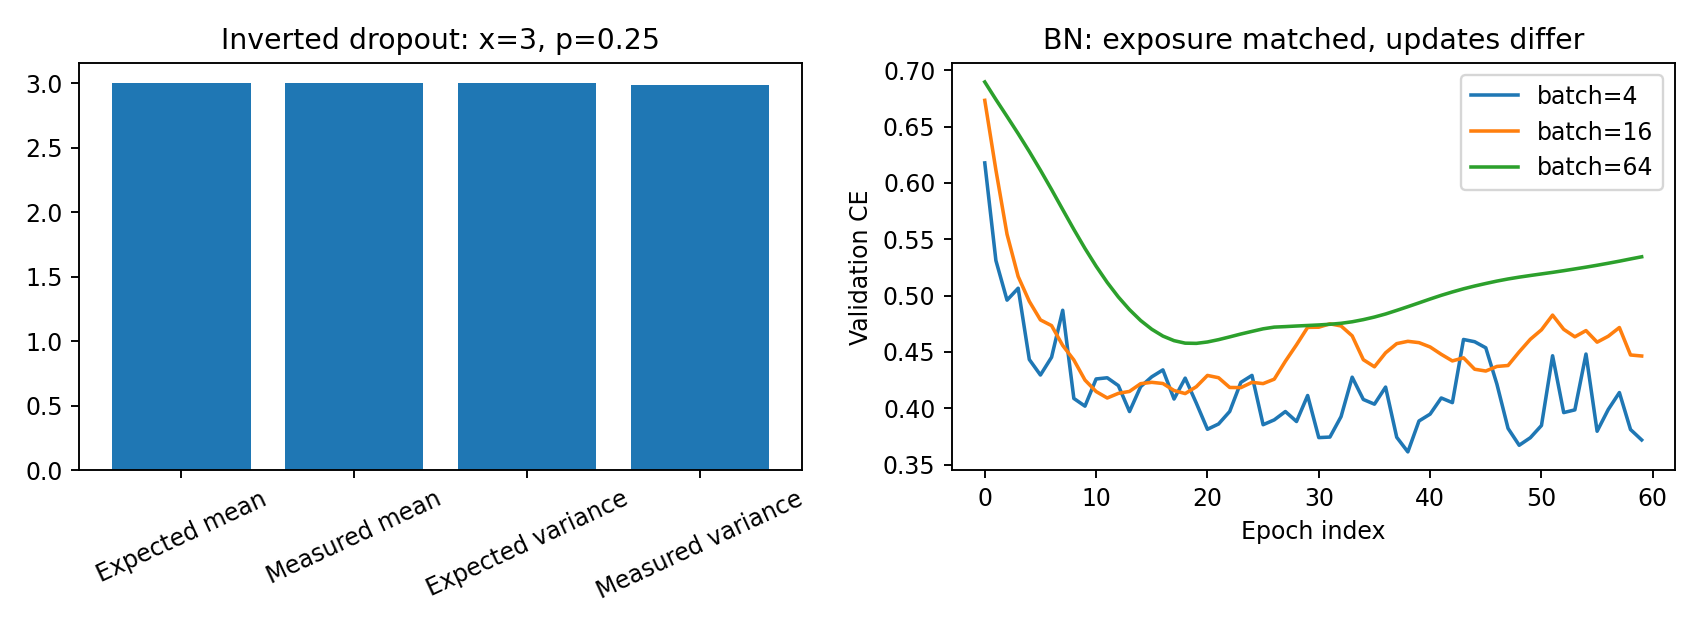

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。